<a href="https://colab.research.google.com/github/muskan-512/ML_AP24110011709/blob/main/Naive_Bayes_8_Cells.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Naive Bayes Classification

#### Name - Muskan
#### Registration Number - AP24110011709
#### Sec - C(CSE-AIML)
## Aim
To build a simple machine-learning model that predicts whether a student will **Pass** or **Fail** using study hours and attendance.

## Theory / Notes
Naive Bayes is a supervised classification algorithm based on **Bayes' theorem**:

P(C|X)=(P(X|C)*P(C))/P(X)

- **P(C | X):** probability of class C after observing features X.(Posterior)
- **P(X | C):** probability of observing X for class C.(Likelihood)
- **P(C):** prior probability of class C.(prior)
- **P(X):** overall probability of the features.(Total Probability)

It is called naive because it assumes the features are conditionally independent given the class.

**Types:** Gaussian, Multinomial, and Bernoulli Naive Bayes.

We use **Gaussian Naive Bayes** because the input features are numerical.

## Cell 2: Import Required Libraries

We use:
- `pandas` to create and manage the dataset.
- `train_test_split` to divide the data.
- `GaussianNB` to build the Naive Bayes classifier.
- Evaluation functions to measure model performance.
- `matplotlib` to display the confusion matrix.

In [ ]:
##Import libraries

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
import seaborn as sns
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully.")

Libraries imported successfully.


## Cell 4: Create the Dataset

This is a small, illustrative dataset created for practice.

- **Study_Hours:** hours spent studying.
- **Attendance:** attendance percentage.
- **Result:** target class (Pass or Fail).

The model will learn to predict the result using the first two columns.

In [ ]:
 ##Create and display the student dataset

data = {
    "Study_Hours": [1, 2, 2, 3, 3, 4, 4, 5, 5, 6,
                    6, 7, 7, 8, 8, 2, 4, 6, 7, 9],
    "Attendance": [45, 50, 55, 60, 58, 65, 70, 72, 75, 78,
                   80, 82, 85, 88, 90, 48, 68, 76, 87, 95],
    "Result": ["Fail", "Fail", "Fail", "Fail", "Fail",
               "Fail", "Pass", "Pass", "Pass", "Pass",
               "Pass", "Pass", "Pass", "Pass", "Pass",
               "Fail", "Pass", "Pass", "Pass", "Pass"]
}




df = pd.DataFrame(data)

print("Student Dataset:")
display(df)
print("\nDataset shape:", df.shape)
print("\nClass counts:")
print(df["Result"].value_counts())

Student Dataset:


,Study_Hours,Attendance,Result
0,1,45,Fail
1,2,50,Fail
2,2,55,Fail
3,3,60,Fail
4,3,58,Fail
5,4,65,Fail
6,4,70,Pass
7,5,72,Pass
8,5,75,Pass
9,6,78,Pass



Dataset shape: (20, 3)

Class counts:
Result
Pass    13
Fail     7
Name: count, dtype: int64


Dataset Shape: (20, 3)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Study_Hours  20 non-null     int64 
 1   Attendance   20 non-null     int64 
 2   Result       20 non-null     object
dtypes: int64(2), object(1)
memory usage: 612.0+ bytes

Missing Values:
Study_Hours    0
Attendance     0
Result         0
dtype: int64

Duplicate Values: 0

Statistical Summary:


,Study_Hours,Attendance
count,20.00000,20.000000
mean,4.95000,71.350000
std,2.32775,14.879428
min,1.00000,45.000000
25%,3.00000,59.500000
50%,5.00000,73.500000
75%,7.00000,82.750000
max,9.00000,95.000000



Result Distribution:
Result
Pass    13
Fail     7
Name: count, dtype: int64


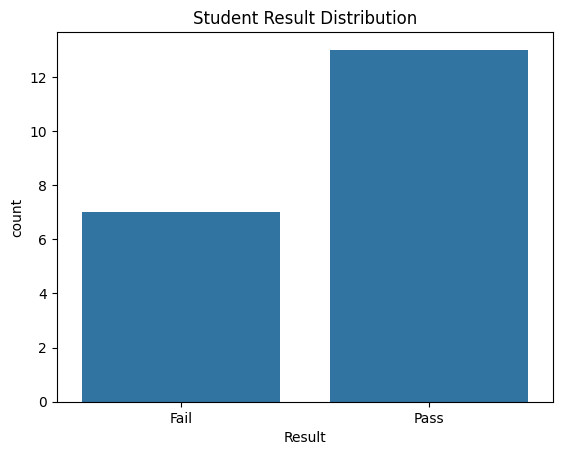

In [ ]:
# EDA

print("Dataset Shape:", df.shape)
print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Values:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())

print("\nResult Distribution:")
print(df["Result"].value_counts())

# Visualization
sns.countplot(data=df, x="Result")
plt.title("Student Result Distribution")
plt.show()

## Cell 6: Split the Data and Train the Model

We separate the dataset into:
- **Features (X):** Study_Hours and Attendance.
- **Target (y):** Result.

We use 75% of the records for training and 25% for testing. The model learns patterns from the training data.

Training records: 15
Testing records: 5
Model training completed.

Accuracy: 100.00%

Classification Report:
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         2
        Pass       1.00      1.00      1.00         3

    accuracy                           1.00         5
   macro avg       1.00      1.00      1.00         5
weighted avg       1.00      1.00      1.00         5



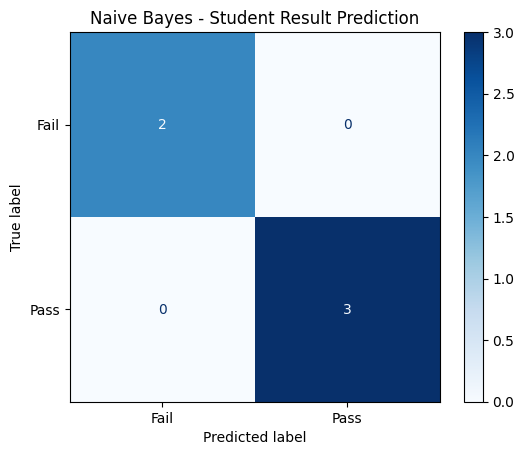

Predicted result for the new student: Pass


In [ ]:
# Cell 7: Split data, train the model, and evaluate it

X = df[["Study_Hours", "Attendance"]]
y = df["Result"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

model = GaussianNB()
model.fit(X_train, y_train)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Model training completed.")

y_pred = model.predict(X_test)

print(f"\nAccuracy: {accuracy_score(y_test, y_pred):.2%}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=["Fail", "Pass"])
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fail", "Pass"]
).plot(cmap="Blues")
plt.title("Naive Bayes - Student Result Prediction")
plt.show()

new_student = pd.DataFrame({
    "Study_Hours": [5],
    "Attendance": [75]
})
prediction = model.predict(new_student)[0]
print("Predicted result for the new student:", prediction)

## Cell 8: Conclusion

Naive Bayes was implemented using the Gaussian Naive Bayes classifier. The model used study hours and attendance to predict whether a student would Pass or Fail.

**Conclusion:** Naive Bayes is a simple, fast classification algorithm based on probability. It is useful as a baseline model for classification tasks.

**Important:** This small, manually created dataset is only for demonstration. Its results should not be used to make real decisions about students.